In [8]:
# Installer le driver PostgreSQL si manquant
try:
    import psycopg
except ModuleNotFoundError:
    %pip install "psycopg[binary]"


In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from urllib.parse import quote_plus
from dotenv import load_dotenv

load_dotenv("../env")

#extract vlues from the .env file
user_db=os.getenv("user_db")
user_password=os.getenv("user_password")
db_host=os.getenv("db_host")
db_port=os.getenv("db_port")
db_name=os.getenv("db_name")

engine=create_engine(f"postgresql://{user_db}:{user_password}@{db_host}:{db_port}/{db_name}")

os.makedirs("../images", exist_ok=True)
sns.set_theme(style="whitegrid")

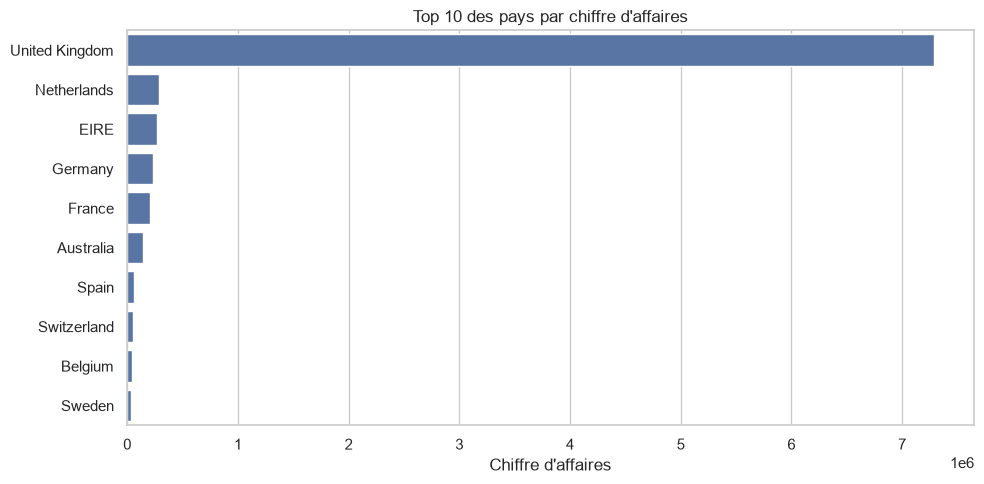

In [13]:
query = """
select "Country", sum("Quantity" * "UnitPrice") as revenue
from sales
group by "Country"
order by revenue desc
limit 10;
"""
df = pd.read_sql(query, engine)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="revenue", y="Country")
plt.title("Top 10 des pays par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/ca_par_pays.png", dpi=150)
plt.show()

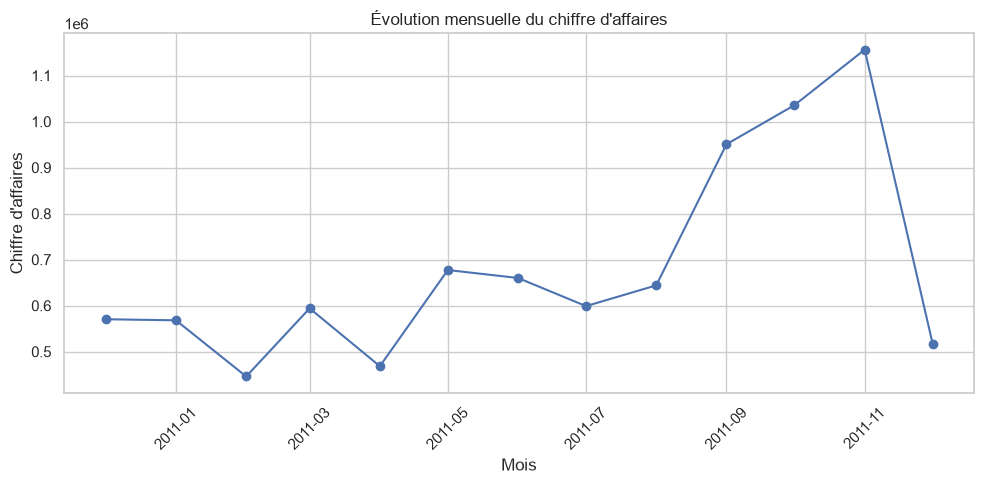

In [14]:
query = """
select date_trunc('month', "InvoiceDate")::date as month,
       sum("Quantity" * "UnitPrice") as revenue
from sales
group by month
order by month;
"""
df = pd.read_sql(query, engine)

plt.figure(figsize=(10, 5))
plt.plot(df["month"], df["revenue"], marker="o")
plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/ca_mensuel.png", dpi=150)
plt.show()

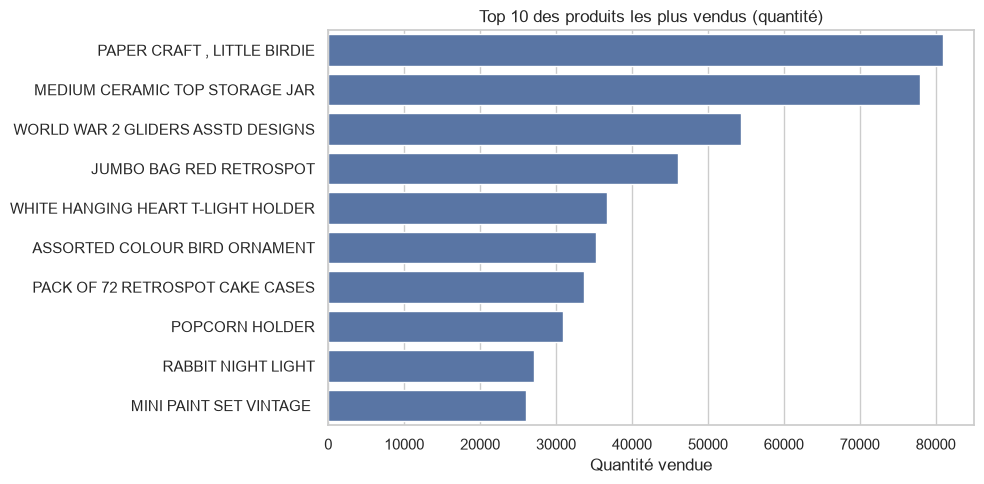

In [ ]:
query = """
select "Description", sum("Quantity") as quantity_sold
from sales
group by "Description"
order by quantity_sold desc
limit 10;
"""
df = pd.read_sql(query, engine)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="quantity_sold", y="Description")
plt.title("Top 10 des produits les plus vendus (quantité)")
plt.xlabel("Quantité vendue")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/top_produits.png", dpi=150)
plt.show()

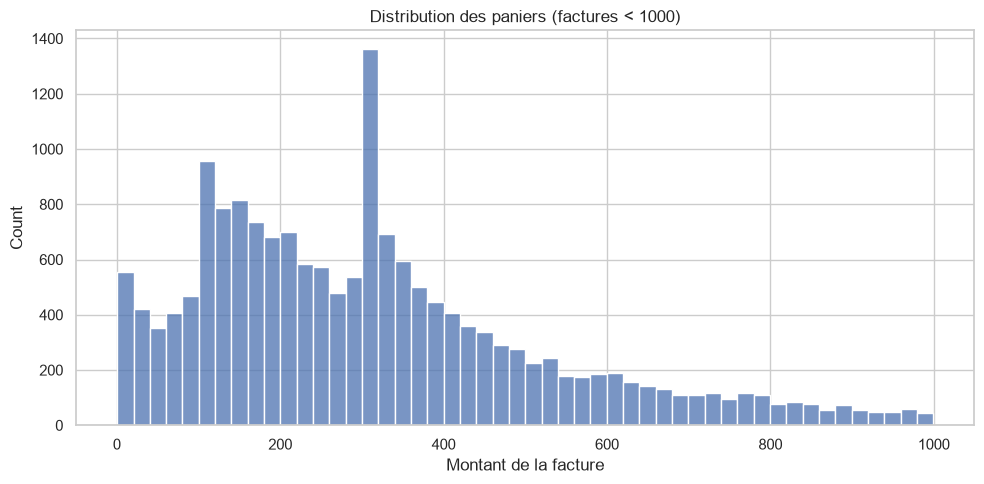

In [ ]:
query = """
select sum("Quantity" * "UnitPrice") as basket
from sales
group by "InvoiceNo";
"""
df = pd.read_sql(query, engine)

plt.figure(figsize=(10, 5))
sns.histplot(df[df["basket"] < 1000]["basket"], bins=50)
plt.title("Distribution des paniers (factures < 1000)")
plt.xlabel("Montant de la facture")
plt.tight_layout()
plt.savefig("../images/distribution_panier.png", dpi=150)
plt.show()

In [ ]:
import sys
print(sys.executable)

c:\Users\admin\Desktop\retail\venv\Scripts\python.exe
